In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt

RAW = Path("../data/raw")
frames = []
for f in RAW.rglob("*.csv"):
    sensor, room = f.stem.lower().split("_room_")
    d = pd.read_csv(f).rename(columns={f"room_{room}": "value"})
    d["sensor"], d["room"] = sensor, int(room)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
raw["minute"] = (pd.to_timedelta(raw["Time"]).dt.total_seconds() // 60).astype(int)
raw["hour"] = raw["minute"] // 60

In [2]:
raw.groupby(["sensor", "room"])["value"].describe().round(2)

count    mean     std     min     25%     50%  \
sensor                 room                                                    
co2                    1     12044.0  575.47  116.90  406.72  494.72  534.72   
                       2     11897.0  498.05   83.71  405.76  440.00  465.92   
                       3     12059.0  556.24  103.49  408.00  488.96  533.76   
humidity               1      6440.0   41.45    9.88   22.75   32.94   40.00   
                       2      7639.0   42.83    8.32   22.75   37.65   41.96   
                       3      5468.0   45.13    9.95   22.75   37.65   45.88   
illuminance            1     24813.0  361.07  258.17    0.00  243.04  315.04   
                       2     23663.0  216.08  197.67    0.00  116.00  195.04   
                       3     21542.0  174.75  126.83    0.00   83.04  184.00   
occupant_count         1     63350.0    8.19   16.23    0.00    0.00    0.00   
                       2     63350.0    4.11    6.56    0.00    0.00    1.00   
                       3     63350.0    3.77    7.21    0.00    0.00    0.00   
occupant_count_cam1_bw 1     63334.0    0.12    0.63    0.00    0.00    0.00   
                       2     63334.0    0.05    0.34    0.00    0.00    0.00   
                       3     63288.0    0.08    0.44    0.00    0.00    0.00   
occupant_count_cam1_fw 1     63334.0    0.12    0.59    0.00    0.00    0.00   
                       2     63334.0    0.04    0.29    0.00    0.00    0.00   
                       3     63288.0    0.08    0.49    0.00    0.00    0.00   
occupant_count_cam2_bw 1     63170.0    0.26    0.99    0.00    0.00    0.00   
                       2     63287.0    0.07    0.42    0.00    0.00    0.00   
                       3     63335.0    0.04    0.28    0.00    0.00    0.00   
occupant_count_cam2_fw 1     63170.0    0.26    0.89    0.00    0.00    0.00   
                       2     63287.0    0.08    0.43    0.00    0.00    0.00   
                       3     63335.0    0.03    0.24    0.00    0.00    0.00   
temperature            1      5200.0   23.26    1.60   19.40   22.10   23.00   
                       2      2457.0   22.63    1.45   17.30   21.80   22.40   
                       3      2352.0   21.59    1.03   15.70   21.00   21.40   
vav                    1       880.0   48.01   39.30    0.00    0.00   45.10   
                       2       659.0   35.57   41.16    0.00    0.00   19.61   
                       3       656.0   48.96   31.64    0.00   22.25   45.10   

                                75%      max  
sensor                 room                   
co2                    1     616.96  1046.40  
                       2     528.96  1160.96  
                       3     595.84  1207.68  
humidity               1      47.84    74.90  
                       2      45.88    75.69  
                       3      52.94    70.98  
illuminance            1     392.96  2064.64  
                       2     240.96  2005.76  
                       3     218.08  1561.60  
occupant_count         1       5.00    80.00  
                       2       5.00    65.00  
                       3       4.00    80.00  
occupant_count_cam1_bw 1       0.00    30.00  
                       2       0.00    14.00  
                       3       0.00    14.00  
occupant_count_cam1_fw 1       0.00    36.00  
                       2       0.00     8.00  
                       3       0.00    27.00  
occupant_count_cam2_bw 1       0.00    43.00  
                       2       0.00    12.00  
                       3       0.00     9.00  
occupant_count_cam2_fw 1       0.00    41.00  
                       2       0.00    12.00  
                       3       0.00     6.00  
temperature            1      24.10    28.40  
                       2      23.50    26.50  
                       3      22.10    24.70  
vav                    1     100.00   100.00  
                       2     100.00   100.00  
             

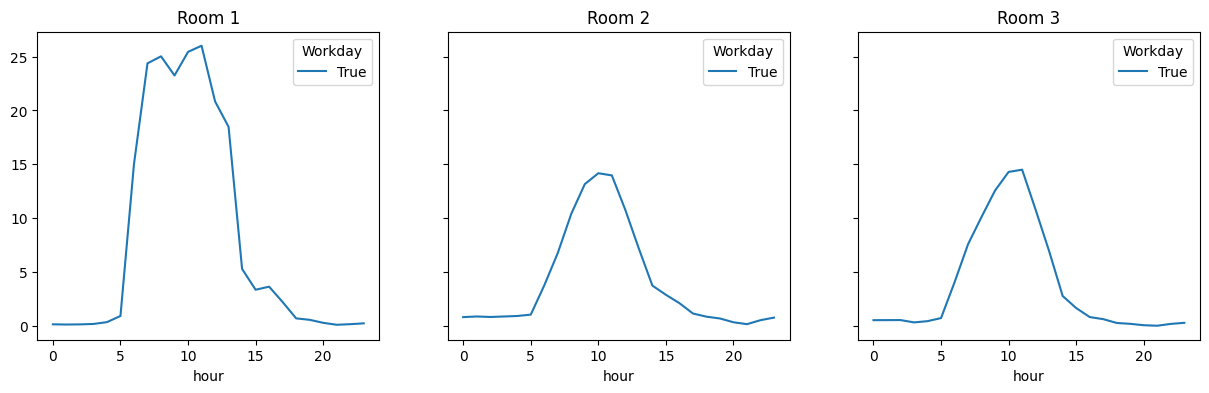

In [3]:
occ = raw[raw.sensor == "occupant_count"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (r, g) in zip(axes, occ.groupby("room")):
    g.groupby(["hour", "Workday"])["value"].mean().unstack().plot(ax=ax, title=f"Room {r}")
plt.show()

In [6]:
cap = {1: 84, 2: 32, 3: 32}

# 1) distribution of occupancy and camera flows per room
for s in ["occupant_count", "occupant_count_cam1_fw", "occupant_count_cam2_bw"]:
    g = raw[raw.sensor == s]
    print(s)
    print(g.groupby("room")["value"].quantile([.5, .99, .999, 1]).unstack().round(1))
    print()

# 2) how often occupancy exceeds capacity (with a 10% tolerance)
occ = raw[raw.sensor == "occupant_count"].copy()
occ["capacity"] = occ["room"].map(cap)
occ["over_cap"] = occ["value"] > occ["capacity"] * 1.1
print("Over-capacity readings per room:")
print(occ.groupby("room")["over_cap"].agg(["sum", "mean"]).round(4))
print()

# 3) daily peak occupancy per room
daily_peak = occ.groupby(["room", "DayId"])["value"].max().unstack(0)
print("Daily peak occupancy summary:")
print(daily_peak.describe().round(1))
print()

# 4) days where the peak exceeds capacity
bad_days = daily_peak.copy()
for r in [1, 2, 3]:
    bad_days[r] = bad_days[r] > cap[r] * 1.1
print("Days with peak over capacity (True = suspect):")
print(bad_days.sum())

occupant_count
      0.500  0.990  0.999  1.000
room                            
1       0.0   68.0   78.0   80.0
2       1.0   27.0   48.0   65.0
3       0.0   31.0   62.0   80.0

occupant_count_cam1_fw
      0.500  0.990  0.999  1.000
room                            
1       0.0    2.0    6.0   36.0
2       0.0    1.0    4.0    8.0
3       0.0    2.0    6.0   27.0

occupant_count_cam2_bw
      0.500  0.990  0.999  1.000
room                            
1       0.0    4.0   12.0   43.0
2       0.0    2.0    5.0   12.0
3       0.0    1.0    4.0    9.0

Over-capacity readings per room:
      sum    mean
room             
1       0  0.0000
2     154  0.0024
3     417  0.0066

Daily peak occupancy summary:
room      1     2     3
count  44.0  44.0  44.0
mean   42.5  21.3  23.0
std    22.6  11.3  13.3
min     3.0   1.0   2.0
25%    30.0  15.8  16.8
50%    44.0  21.5  20.5
75%    57.2  28.2  27.5
max    80.0  65.0  80.0

Days with peak over capacity (True = suspect):
room
1    0
2    1
3   

            min_over  peak  mins  workday  month
room DayId                                      
3    17          201  80.0  1440     True     10
2    17          154  65.0  1440     True     10
3    42          104  47.0  1440     True      3
     13           96  48.0  1440     True      9
     18           13  36.0  1440     True     11
     34            2  36.0  1440     True      5
     37            1  36.0  1440     True     11


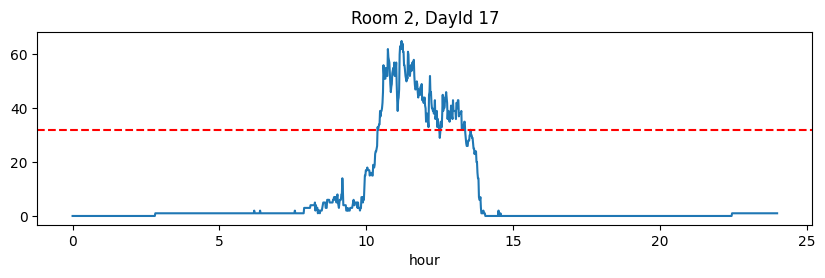

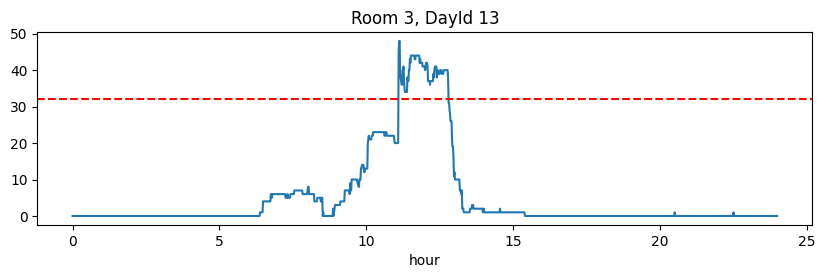

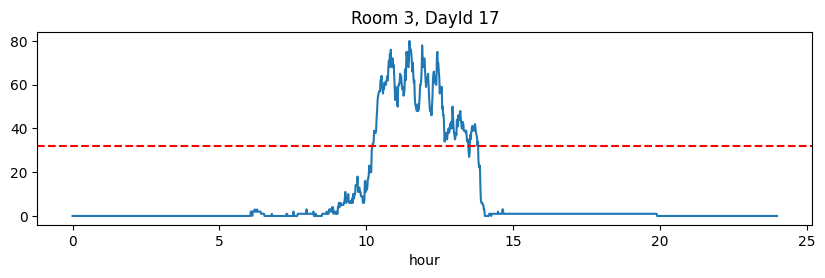

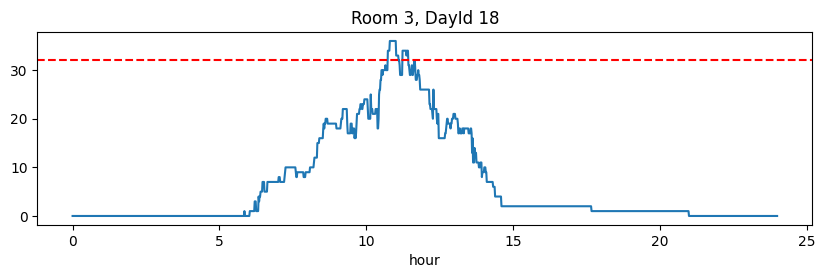

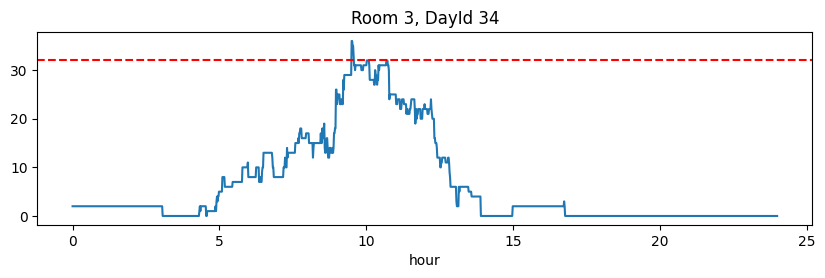

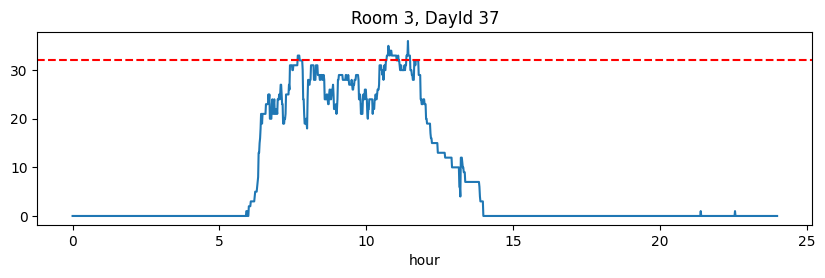

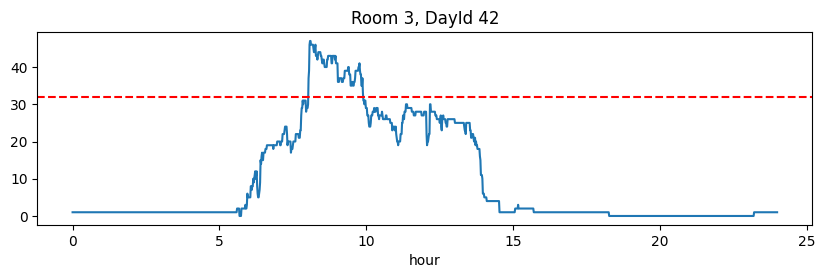

In [7]:
cap = {1: 84, 2: 32, 3: 32}
occ = raw[raw.sensor == "occupant_count"].copy()
occ["capacity"] = occ["room"].map(cap)
occ["over_cap"] = occ["value"] > occ["capacity"] * 1.1

# per room/day: how many minutes over capacity, peak value, and total minutes
sus = (occ.groupby(["room", "DayId"])
          .agg(min_over=("over_cap", "sum"), peak=("value", "max"), mins=("value", "size"),
               workday=("Workday", "first"), month=("Month", "first"))
          .query("min_over > 0"))
print(sus.sort_values("min_over", ascending=False))

# plot each suspect day against the room's capacity
for (r, d) in sus.index:
    day = occ[(occ.room == r) & (occ.DayId == d)]
    plt.figure(figsize=(10, 2.5))
    plt.plot(day["minute"] / 60, day["value"])
    plt.axhline(cap[r], color="r", ls="--")
    plt.title(f"Room {r}, DayId {d}"); plt.xlabel("hour"); plt.show()

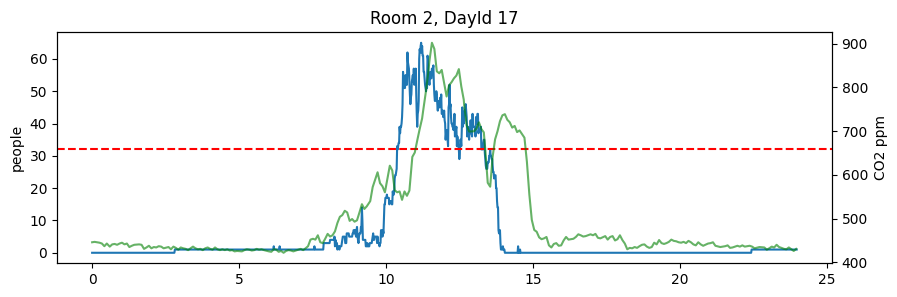

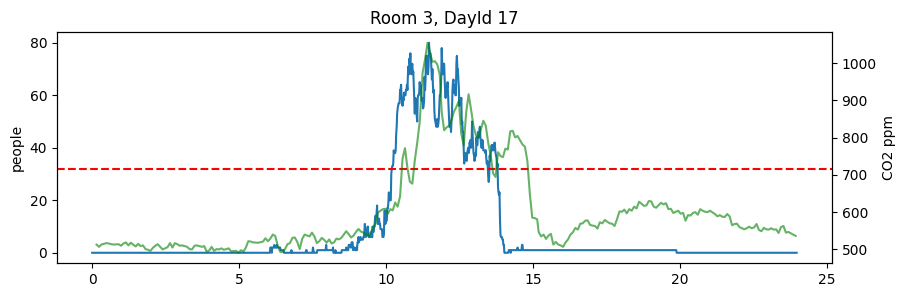

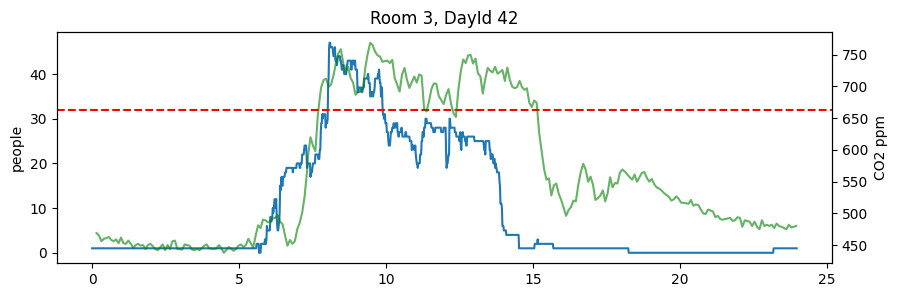

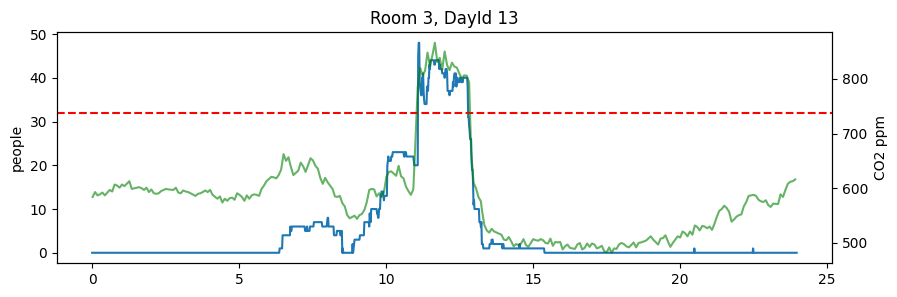

      count   mean    std    min    25%    50%    75%     max
room                                                         
1      44.0  852.0  163.0  502.0  762.0  923.0  968.0  1046.0
2      44.0  721.0  138.0  472.0  628.0  714.0  754.0  1161.0
3      44.0  766.0  180.0  471.0  654.0  764.0  855.0  1208.0


In [8]:
def co2_day(r, d):
    c = raw[(raw.sensor == "co2") & (raw.room == r) & (raw.DayId == d)]
    return c["minute"] / 60, c["value"]

for r, d in [(2, 17), (3, 17), (3, 42), (3, 13)]:
    day = occ[(occ.room == r) & (occ.DayId == d)]
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(day["minute"] / 60, day["value"], label="occupancy")
    ax.axhline(cap[r], color="r", ls="--")
    ax.set_ylabel("people")
    ax2 = ax.twinx()
    x, y = co2_day(r, d)
    ax2.plot(x, y, color="g", alpha=.6)
    ax2.set_ylabel("CO2 ppm")
    ax.set_title(f"Room {r}, DayId {d}")
    plt.show()

# typical CO2 peak per room, for comparison
print(raw[raw.sensor == "co2"].groupby(["room", "DayId"])["value"].max().groupby("room").describe().round(0))

In [9]:
rows = []
for r, d in [(2, 17), (3, 17), (3, 42), (3, 13)]:
    c = raw[(raw.sensor == "co2") & (raw.room == r)]
    day_c = c[c.DayId == d]["value"]
    all_peaks = c.groupby("DayId")["value"].max()

    # 5-min binned correlation between occupancy and CO2 on that day
    def b(s):
        x = raw[(raw.sensor == s) & (raw.room == r) & (raw.DayId == d)].copy()
        x["bin"] = x["minute"] // 5
        return x.groupby("bin")["value"].mean()
    j = pd.concat([b("occupant_count"), b("co2")], axis=1, keys=["occ", "co2"])
    j["co2"] = j["co2"].ffill()
    j = j.dropna()

    # occupancy at the hour of the peak, and whether it ever drops back below capacity
    o = occ[(occ.room == r) & (occ.DayId == d)]["value"]
    rows.append({
        "room": r, "DayId": d,
        "co2_peak": round(day_c.max()),
        "co2_peak_pctile_vs_other_days": round((all_peaks < day_c.max()).mean() * 100),
        "occ_vs_co2_corr": round(j.corr().iloc[0, 1], 2),
        "occ_min": o.min(), "occ_end": o.iloc[-1],
    })
pd.DataFrame(rows)

,room,DayId,co2_peak,co2_peak_pctile_vs_other_days,occ_vs_co2_corr,occ_min,occ_end
0,2,17,902,89,0.80,0.0,1.0
1,3,17,1055,89,0.81,0.0,0.0
2,3,42,769,52,0.78,0.0,1.0
3,3,13,866,75,0.84,0.0,0.0


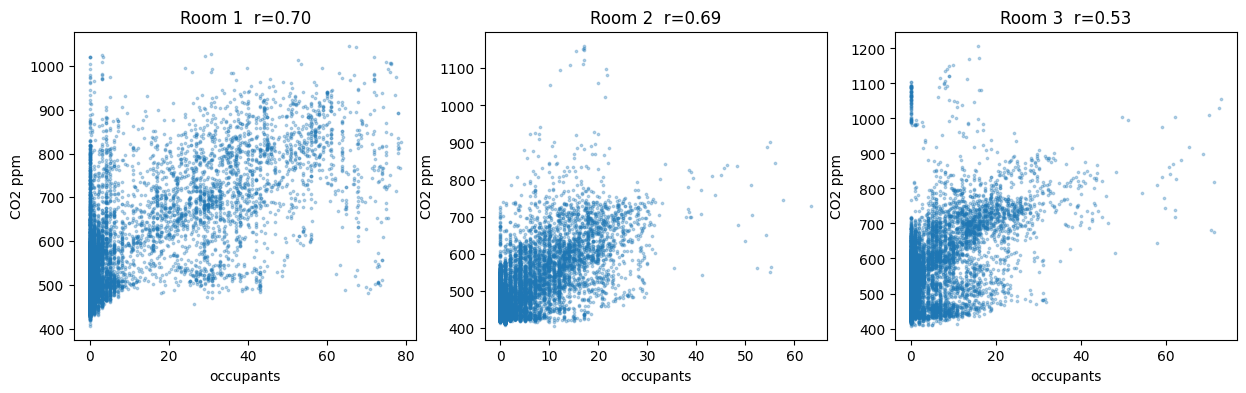

In [10]:
def binned(sensor, room):
    d = raw[(raw.sensor == sensor) & (raw.room == room)].copy()
    d["bin"] = d["minute"] // 5
    return d.groupby(["DayId", "bin"])["value"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axes, [1, 2, 3]):
    x = pd.concat([binned("occupant_count", r), binned("co2", r)], axis=1,
                  keys=["occ", "co2"])
    x["co2"] = x["co2"].groupby(level=0).ffill()
    x = x.dropna()
    ax.scatter(x.occ, x.co2, s=3, alpha=.3)
    ax.set_title(f"Room {r}  r={x.corr().iloc[0,1]:.2f}")
    ax.set_xlabel("occupants"); ax.set_ylabel("CO2 ppm")
plt.show()

In [11]:
for r in [1, 2, 3]:
    net = 0
    for cam in ["cam1", "cam2"]:
        fw = raw[(raw.sensor == f"occupant_count_{cam}_fw") & (raw.room == r)].groupby("DayId")["value"].sum()
        bw = raw[(raw.sensor == f"occupant_count_{cam}_bw") & (raw.room == r)].groupby("DayId")["value"].sum()
        net = net + (fw - bw)
    end = occ[occ.room == r].groupby("DayId")["value"].last()
    comb = pd.concat([net, end], axis=1, keys=["net_flow", "end_occ"])
    print(f"Room {r}: corr={comb.corr().iloc[0,1]:.2f}, "
          f"mean net_flow={comb.net_flow.mean():.1f}, mean end_occ={comb.end_occ.mean():.1f}")

Room 1: corr=-0.06, mean net_flow=0.9, mean end_occ=0.2
Room 2: corr=-0.01, mean net_flow=-2.0, mean end_occ=0.7
Room 3: corr=-0.24, mean net_flow=-0.5, mean end_occ=0.3


## EDA conclusions
- 44 separate days, all sensors present for all 3 rooms.
- Room 1 never exceeds capacity. Rooms 2 and 3 have minor camera spikes, which will be clipped.
- Days (2,17), (3,17), (3,42), (3,13) are over capacity but CO2-supported: kept and flagged as event_day.
- Temperature, humidity and VAV are event-driven (irregular), so they will be forward-filled within each day.
- CO2 vs occupancy correlation: R1 0.70, R2 0.69, R3 0.53 (same-time). Lagged CO2 features should help, especially in Room 3.
- Camera in/out flows balance to within ~1% per day, so no drift correction is needed.